# Dr. Semmelweis and the discovery of handwashing

In the 1840s, as many as one in ten women giving birth at the Vienna General Hospital died of childbed fever. Ignaz Semmelweis, a physician there, suspected that doctors were carrying something on their hands from the autopsy room to the maternity ward, and in mid-1847 he made handwashing with chlorinated lime mandatory.

This notebook re-analyses the data he collected: yearly births and deaths at the hospital's two clinics (1841-1846), and monthly figures for Clinic 1 (1841-1849).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

yearly = pd.read_csv("datasets/yearly_deaths_by_clinic.csv")
yearly["proportion_deaths"] = yearly["deaths"] / yearly["births"]
yearly

,year,births,deaths,clinic,proportion_deaths
0,1841,3036,237,clinic 1,0.078063
1,1842,3287,518,clinic 1,0.157591
2,1843,3060,274,clinic 1,0.089542
3,1844,3157,260,clinic 1,0.082357
4,1845,3492,241,clinic 1,0.069015
5,1846,4010,459,clinic 1,0.114464
6,1841,2442,86,clinic 2,0.035217
7,1842,2659,202,clinic 2,0.075968
8,1843,2739,164,clinic 2,0.059876
9,1844,2956,68,clinic 2,0.023004


## 1. Two clinics, very different death rates

Clinic 1 was staffed by medical students, who also performed autopsies. Clinic 2 was staffed by midwife students, who did not.

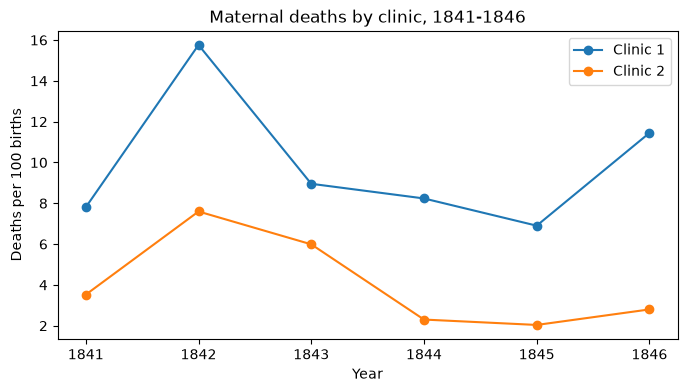

,births,deaths,proportion_deaths
clinic,,,
clinic 1,20042,1989,0.099
clinic 2,17791,691,0.039


In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
for clinic, grp in yearly.groupby("clinic"):
    ax.plot(grp["year"], grp["proportion_deaths"] * 100, marker="o", label=clinic.capitalize())
ax.set_xlabel("Year")
ax.set_ylabel("Deaths per 100 births")
ax.set_title("Maternal deaths by clinic, 1841-1846")
ax.legend()
plt.show()

yearly.groupby("clinic")[["births", "deaths"]].sum().assign(
    proportion_deaths=lambda d: (d["deaths"] / d["births"]).round(3))

## 2. Monthly data for Clinic 1

In [3]:
monthly = pd.read_csv("datasets/monthly_deaths.csv", parse_dates=["date"])
monthly["proportion_deaths"] = monthly["deaths"] / monthly["births"]
monthly.head()

,date,births,deaths,proportion_deaths
0,1841-01-01,254,37,0.145669
1,1841-02-01,239,18,0.075314
2,1841-03-01,277,12,0.043321
3,1841-04-01,255,4,0.015686
4,1841-05-01,255,2,0.007843


## 3. Before and after handwashing

Handwashing became mandatory on 1 June 1847.

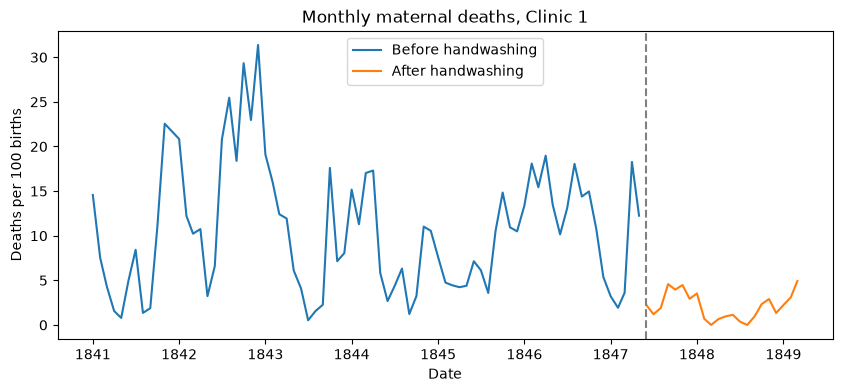

In [4]:
handwashing_start = pd.to_datetime("1847-06-01")
before_washing = monthly[monthly["date"] < handwashing_start]
after_washing = monthly[monthly["date"] >= handwashing_start]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(before_washing["date"], before_washing["proportion_deaths"] * 100, label="Before handwashing")
ax.plot(after_washing["date"], after_washing["proportion_deaths"] * 100, label="After handwashing")
ax.axvline(handwashing_start, color="grey", linestyle="--")
ax.set_xlabel("Date")
ax.set_ylabel("Deaths per 100 births")
ax.set_title("Monthly maternal deaths, Clinic 1")
ax.legend()
plt.show()

In [5]:
before_proportion = before_washing["proportion_deaths"]
after_proportion = after_washing["proportion_deaths"]
mean_diff = after_proportion.mean() - before_proportion.mean()

print(f"Mean monthly death rate before: {before_proportion.mean():.1%}  ({len(before_proportion)} months)")
print(f"Mean monthly death rate after:  {after_proportion.mean():.1%}  ({len(after_proportion)} months)")
print(f"Difference: {mean_diff * 100:.1f} percentage points")

Mean monthly death rate before: 10.5%  (76 months)
Mean monthly death rate after:  2.1%  (22 months)
Difference: -8.4 percentage points


## 4. How certain is the effect?

A bootstrap gives a confidence interval for the difference in means: resample the months before and after with replacement 10,000 times and recompute the difference each time. The random generator is seeded so the numbers are reproducible.

95% confidence interval: -10.1 to -6.6 percentage points


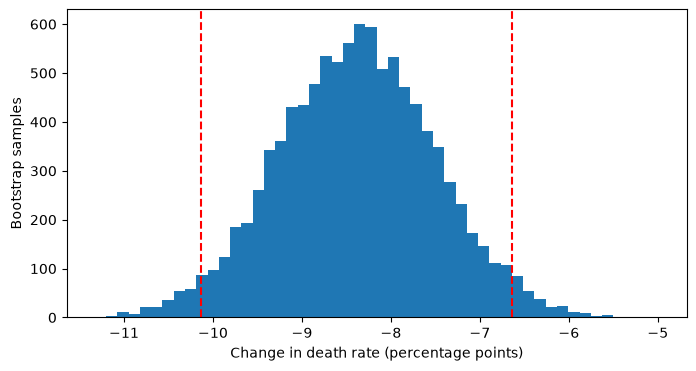

In [6]:
rng = np.random.default_rng(42)
before_values = before_proportion.to_numpy()
after_values = after_proportion.to_numpy()

boot_mean_diff = np.array([
    rng.choice(after_values, size=len(after_values)).mean()
    - rng.choice(before_values, size=len(before_values)).mean()
    for _ in range(10_000)
])
ci_low, ci_high = np.quantile(boot_mean_diff, [0.025, 0.975])
print(f"95% confidence interval: {ci_low * 100:.1f} to {ci_high * 100:.1f} percentage points")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(boot_mean_diff * 100, bins=50)
ax.axvline(ci_low * 100, color="red", linestyle="--")
ax.axvline(ci_high * 100, color="red", linestyle="--")
ax.set_xlabel("Change in death rate (percentage points)")
ax.set_ylabel("Bootstrap samples")
plt.show()

A permutation test asks the complementary question: if handwashing made no difference, how often would shuffling the before/after labels produce a gap this large?

In [7]:
all_values = monthly["proportion_deaths"].to_numpy()
n_after = len(after_values)

perm_diffs = np.empty(10_000)
for i in range(10_000):
    shuffled = rng.permutation(all_values)
    perm_diffs[i] = shuffled[:n_after].mean() - shuffled[n_after:].mean()

p_value = (perm_diffs <= mean_diff).mean()
print(f"Permutations with a drop at least as large as observed: {int((perm_diffs <= mean_diff).sum())} of 10,000 (p = {p_value:.4f})")

Permutations with a drop at least as large as observed: 0 of 10,000 (p = 0.0000)


## Findings

- Between 1841 and 1846, 9.9% of women giving birth in Clinic 1 died, against 3.9% in Clinic 2. The only systematic difference was who staffed the clinic.
- After handwashing became mandatory, the average monthly death rate in Clinic 1 fell from 10.5% to 2.1%, a drop of 8.4 percentage points (95% bootstrap interval: 6.6 to 10.1).
- In 10,000 random relabellings of the months, none produced a drop this large, so chance is not a plausible explanation.

This is a before/after comparison rather than a controlled experiment, so on its own it cannot rule out something else changing in mid-1847. The earlier gap between the two clinics, and the fact that the change is immediate and sustained, make handwashing by far the most convincing explanation. Semmelweis's conclusion was rejected by most of his contemporaries; germ theory only became accepted decades later.